In [34]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/Users/swayamarora/miniforge3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# ****1. Data Preprocessing****

# Import libraries and load dataset

In [35]:
import pandas as pd
import numpy as np
import os

print("Current folder:", os.getcwd())
print("Files:", os.listdir())

df = pd.read_csv("Car details v3.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Current folder: /Users/swayamarora/Desktop/PBL
Files: ['requirements.txt', 'notebook.ipynb', 'cleaned_car_data.csv', 'Car details v3.csv', 'feature_engineered_car_data.csv', 'app.py', 'used_car_price_model.pkl']
Dataset loaded successfully!
Dataset shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


# Inspect the dataset

In [36]:
print("Dataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB

First 5 Records:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0



Last 5 Records:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0
8127,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,8128,2058,Maruti Swift Dzire VDI,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,8128.0,NaN,NaN,NaN,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,NaN,NaN,NaN,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,NaN,NaN,NaN,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,8128,3,Individual,6766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,8128,2,Manual,7078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,7907,393,18.9 kmpl,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,7907,121,1248 CC,1017,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Check missing values and duplicates

In [37]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

print("Missing Values:")
display(missing_values)

print("Total Duplicate Rows:", df.duplicated().sum())

Missing Values:


,Missing Count,Missing Percentage
name,0,0.00
year,0,0.00
selling_price,0,0.00
km_driven,0,0.00
fuel,0,0.00
seller_type,0,0.00
transmission,0,0.00
owner,0,0.00
mileage,221,2.72
engine,221,2.72


Total Duplicate Rows: 1202


# Clean the data

In [38]:
# Create a copy of the original dataset
cleaned_df = df.copy()

# Standardize column names
cleaned_df.columns = [
    col.strip().lower().replace(" ", "_")
    for col in cleaned_df.columns
]

# Remove unnecessary spaces from text columns
text_columns = [
    "name", "fuel", "seller_type",
    "transmission", "owner"
]

for col in text_columns:
    cleaned_df[col] = (
        cleaned_df[col]
        .astype("string")
        .str.strip()
        .replace({"": pd.NA, "-": pd.NA, "nan": pd.NA})
    )

# Standardize categorical values
categorical_columns = [
    "fuel", "seller_type", "transmission", "owner"
]

for col in categorical_columns:
    cleaned_df[col] = cleaned_df[col].str.title()

# Convert important columns into numeric format
numeric_columns = [
    "year", "selling_price", "km_driven", "seats"
]

for col in numeric_columns:
    cleaned_df[col] = pd.to_numeric(
        cleaned_df[col], errors="coerce"
    )

# Remove exact duplicate rows
before_duplicates = len(cleaned_df)

cleaned_df = cleaned_df.drop_duplicates().copy()

duplicates_removed = before_duplicates - len(cleaned_df)

print("Duplicate Rows Removed:", duplicates_removed)

Duplicate Rows Removed: 1202


# Remove invalid records

In [39]:
REFERENCE_YEAR = 2026

invalid_target = (
    cleaned_df["selling_price"].isna() |
    (cleaned_df["selling_price"] <= 0)
)

invalid_year = (
    cleaned_df["year"].isna() |
    (cleaned_df["year"] < 1900) |
    (cleaned_df["year"] > REFERENCE_YEAR)
)

invalid_distance = (
    cleaned_df["km_driven"].isna() |
    (cleaned_df["km_driven"] < 0)
)

invalid_rows = (
    invalid_target |
    invalid_year |
    invalid_distance
)

invalid_count = invalid_rows.sum()

cleaned_df = cleaned_df.loc[~invalid_rows].copy()

print("Invalid Rows Removed:", invalid_count)
print("Rows After Cleaning:", len(cleaned_df))
print("Columns:", cleaned_df.shape[1])

Invalid Rows Removed: 0
Rows After Cleaning: 6926
Columns: 13


# Display and save cleaned dataset

In [40]:
print("Final Cleaned Dataset:")
display(cleaned_df.head())

print("\nMissing Values After Cleaning:")
display(cleaned_df.isnull().sum())

cleaned_df.to_csv("cleaned_car_data.csv", index=False)
print("Cleaned dataset saved successfully!")

print("Cleaned dataset saved successfully!")

Final Cleaned Dataset:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0



Missing Values After Cleaning:


name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
dtype: int64

Cleaned dataset saved successfully!
Cleaned dataset saved successfully!


# ****2. Feature engineering****

# Load the cleaned dataset

In [41]:
import pandas as pd
import numpy as np

df = cleaned_df.copy()

print("Dataset Loaded:", df.shape)
display(df.head())

Dataset Loaded: (6926, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


# Extract brand from car name

In [42]:
def extract_brand(name):
    if pd.isna(name) or not str(name).strip():
        return np.nan

    return str(name).strip().split()[0].title()

df["brand"] = df["name"].apply(extract_brand)

print("Brand Feature Created!")
display(df[["name", "brand"]].head(10))

Brand Feature Created!


,name,brand
0,Maruti Swift Dzire VDI,Maruti
1,Skoda Rapid 1.5 TDI Ambition,Skoda
2,Honda City 2017-2020 EXi,Honda
3,Hyundai i20 Sportz Diesel,Hyundai
4,Maruti Swift VXI BSIII,Maruti
5,Hyundai Xcent 1.2 VTVT E Plus,Hyundai
6,Maruti Wagon R LXI DUO BSIII,Maruti
7,Maruti 800 DX BSII,Maruti
8,Toyota Etios VXD,Toyota
9,Ford Figo Diesel Celebration Edition,Ford


# Calculate vehicle age

In [43]:
REFERENCE_YEAR = 2026

df["vehicle_age"] = REFERENCE_YEAR - df["year"]

print("Vehicle Age Feature Created!")

display(
    df[["name", "year", "vehicle_age"]].head(10)
)

Vehicle Age Feature Created!


,name,year,vehicle_age
0,Maruti Swift Dzire VDI,2014,12
1,Skoda Rapid 1.5 TDI Ambition,2014,12
2,Honda City 2017-2020 EXi,2006,20
3,Hyundai i20 Sportz Diesel,2010,16
4,Maruti Swift VXI BSIII,2007,19
5,Hyundai Xcent 1.2 VTVT E Plus,2017,9
6,Maruti Wagon R LXI DUO BSIII,2007,19
7,Maruti 800 DX BSII,2001,25
8,Toyota Etios VXD,2011,15
9,Ford Figo Diesel Celebration Edition,2013,13


# Convert specifications into numeric values

In [44]:
def convert_to_numeric(series):
    return pd.to_numeric(
        series.astype("string").str.extract(
            r"([-+]?[0-9]*\.?[0-9]+)",
            expand=False
        ),
        errors="coerce"
    )

specification_columns = [
    "mileage",
    "engine",
    "max_power"
]

for col in specification_columns:
    df[col] = convert_to_numeric(df[col])

print("Specifications Converted Successfully!")

display(
    df[
        ["mileage", "engine", "max_power"]
    ].head(10)
)

Specifications Converted Successfully!


,mileage,engine,max_power
0,23.4,1248,74.0
1,21.14,1498,103.52
2,17.7,1497,78.0
3,23.0,1396,90.0
4,16.1,1298,88.2
5,20.14,1197,81.86
6,17.3,1061,57.5
7,16.1,796,37.0
8,23.59,1364,67.1
9,20.0,1399,68.1


# Display the final engineered dataset

In [45]:
print("Final Dataset Shape:", df.shape)

display(
    df[
        [
            "name",
            "brand",
            "year",
            "vehicle_age",
            "mileage",
            "engine",
            "max_power"
        ]
    ].head(10)
)

df.to_csv("feature_engineered_car_data.csv", index=False)

print("Feature-engineered dataset saved successfully!")

print("Feature-engineered dataset saved!")

Final Dataset Shape: (6926, 15)


,name,brand,year,vehicle_age,mileage,engine,max_power
0,Maruti Swift Dzire VDI,Maruti,2014,12,23.4,1248,74.0
1,Skoda Rapid 1.5 TDI Ambition,Skoda,2014,12,21.14,1498,103.52
2,Honda City 2017-2020 EXi,Honda,2006,20,17.7,1497,78.0
3,Hyundai i20 Sportz Diesel,Hyundai,2010,16,23.0,1396,90.0
4,Maruti Swift VXI BSIII,Maruti,2007,19,16.1,1298,88.2
5,Hyundai Xcent 1.2 VTVT E Plus,Hyundai,2017,9,20.14,1197,81.86
6,Maruti Wagon R LXI DUO BSIII,Maruti,2007,19,17.3,1061,57.5
7,Maruti 800 DX BSII,Maruti,2001,25,16.1,796,37.0
8,Toyota Etios VXD,Toyota,2011,15,23.59,1364,67.1
9,Ford Figo Diesel Celebration Edition,Ford,2013,13,20.0,1399,68.1


Feature-engineered dataset saved successfully!
Feature-engineered dataset saved!


# ****3. Exploratory Data Analysis (EDA)****

# Import libraries and load data

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("feature_engineered_car_data.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (6926, 15)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,brand,vehicle_age
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190Nm@ 2000rpm,5.0,Maruti,12
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250Nm@ 1500-2500rpm,5.0,Skoda,12
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,"12.7@ 2,700(kgm@ rpm)",5.0,Honda,20
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,22.4 kgm at 1750-2750rpm,5.0,Hyundai,16
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,"11.5@ 4,500(kgm@ rpm)",5.0,Maruti,19


# Selling price distribution

/Users/swayamarora/miniforge3/lib/python3.12/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/swayamarora/miniforge3/lib/python3.12/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/swayamarora/miniforge3/lib/python3.12/site-packages/scipy/_lib/_util.py:1279: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


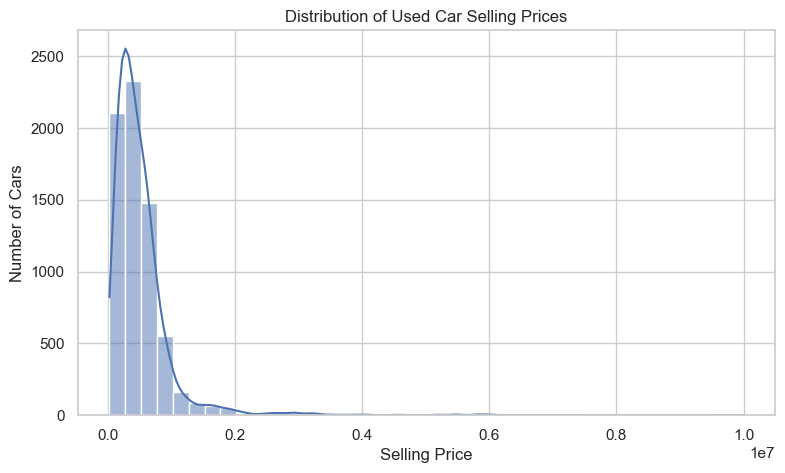

In [47]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df["selling_price"],
    bins=40,
    kde=True
)

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.show()

# Selling price vs manufacturing year

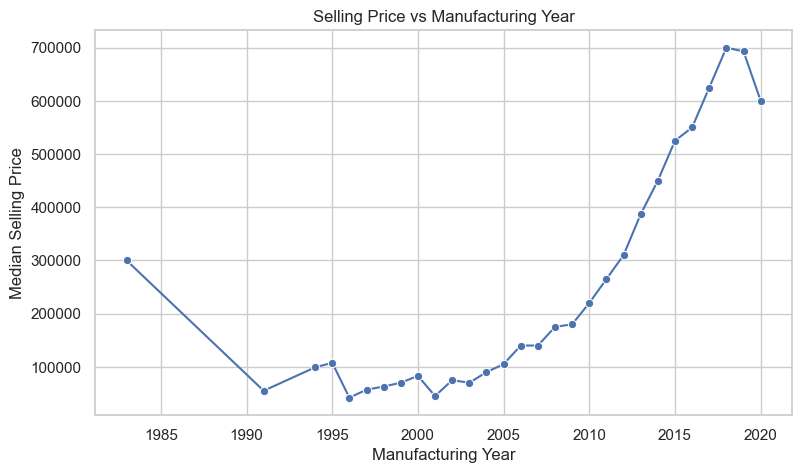

In [48]:
plt.figure(figsize=(9, 5))

yearly_prices = df.groupby("year")["selling_price"].median().reset_index()

sns.lineplot(
    data=yearly_prices,
    x="year",
    y="selling_price",
    marker="o"
)

plt.title("Selling Price vs Manufacturing Year")
plt.xlabel("Manufacturing Year")
plt.ylabel("Median Selling Price")

plt.show()

# Selling price vs kilometres driven

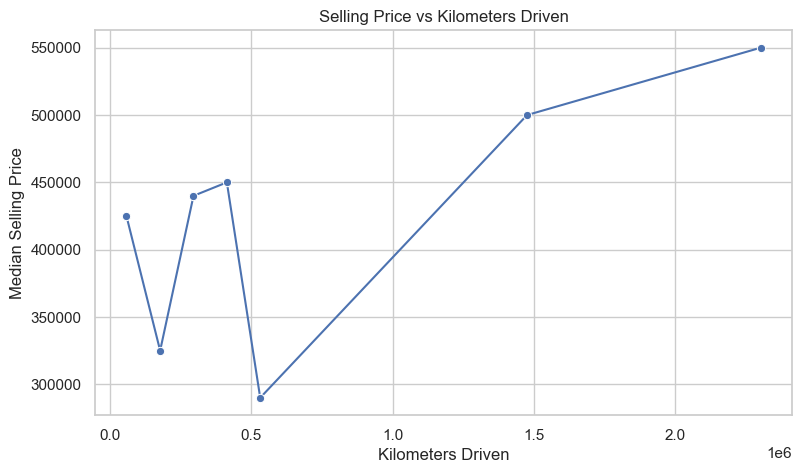

In [49]:
plt.figure(figsize=(9, 5))

df["km_group"] = pd.cut(df["km_driven"], bins=20)

km_prices = (
    df.groupby("km_group", observed=True)["selling_price"]
    .median()
    .reset_index()
)

km_prices["km_midpoint"] = km_prices["km_group"].apply(
    lambda x: x.mid
)

sns.lineplot(
    data=km_prices,
    x="km_midpoint",
    y="selling_price",
    marker="o"
)

plt.title("Selling Price vs Kilometers Driven")
plt.xlabel("Kilometers Driven")
plt.ylabel("Median Selling Price")

plt.show()

# Price comparison by fuel type

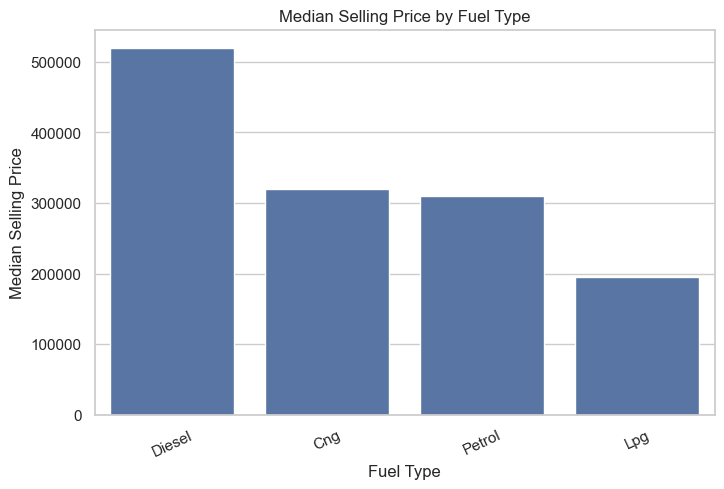

In [50]:
fuel_prices = (
    df.groupby("fuel")["selling_price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=fuel_prices.index,
    y=fuel_prices.values
)

plt.title("Median Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Median Selling Price")
plt.xticks(rotation=25)

plt.show()

# Price comparison by transmission

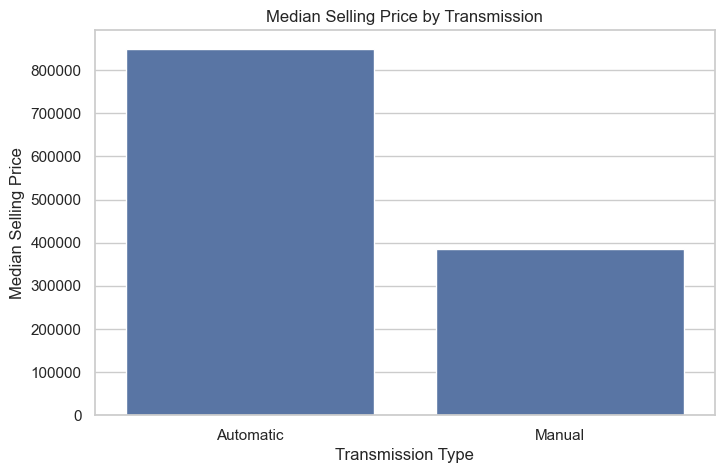

In [51]:
transmission_prices = (
    df.groupby("transmission")["selling_price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=transmission_prices.index,
    y=transmission_prices.values
)

plt.title("Median Selling Price by Transmission")
plt.xlabel("Transmission Type")
plt.ylabel("Median Selling Price")

plt.show()

# Price comparison by brand

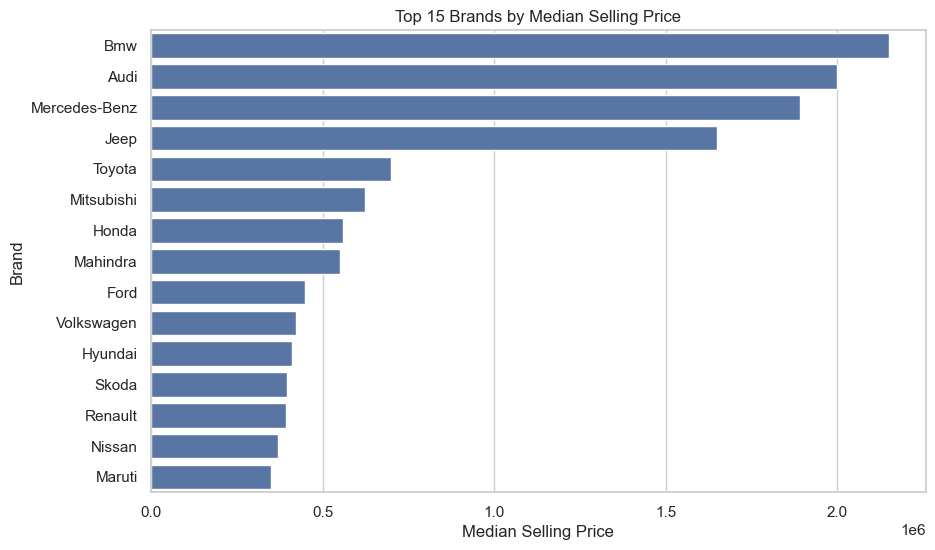

In [52]:
brand_counts = df["brand"].value_counts()

common_brands = brand_counts[
    brand_counts >= 10
].index

brand_prices = (
    df[df["brand"].isin(common_brands)]
    .groupby("brand")["selling_price"]
    .median()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=brand_prices.values,
    y=brand_prices.index
)

plt.title("Top 15 Brands by Median Selling Price")
plt.xlabel("Median Selling Price")
plt.ylabel("Brand")

plt.show()

# Outlier detection using boxplots

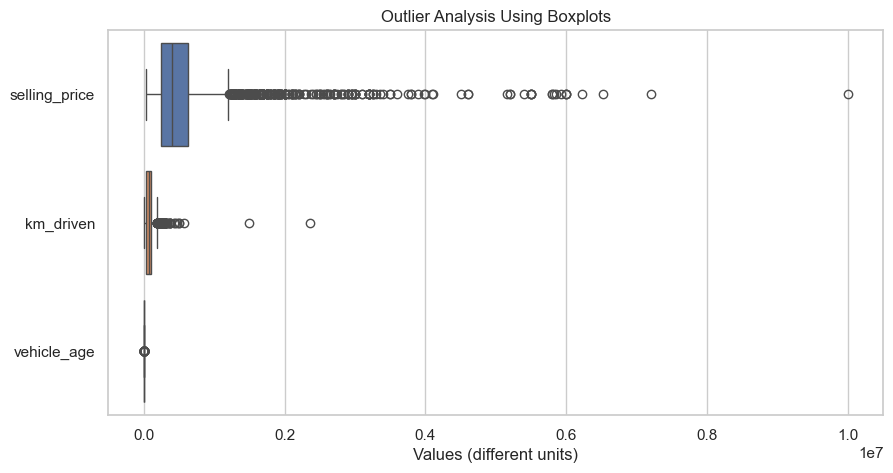

In [53]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df[
        [
            "selling_price",
            "km_driven",
            "vehicle_age"
        ]
    ],
    orient="h"
)

plt.title("Outlier Analysis Using Boxplots")
plt.xlabel("Values (different units)")

plt.show()

# IQR outlier summary

In [54]:
columns = [
    "selling_price",
    "km_driven",
    "vehicle_age",
    "engine",
    "max_power",
    "mileage"
]

outlier_results = []

for col in columns:

    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Feature,Q1,Q3,Lower Bound,Upper Bound,Outlier Count
0,selling_price,250000.0,633500.0,-325250.00,1208750.00,328
1,km_driven,40000.0,100000.0,-50000.00,190000.00,167
2,vehicle_age,9.0,15.0,0.00,24.00,77
3,engine,1197.0,1498.0,745.50,1949.50,1207
4,max_power,67.1,100.0,17.75,149.35,307
5,mileage,16.8,22.5,8.25,31.05,21


# Correlation heatmap

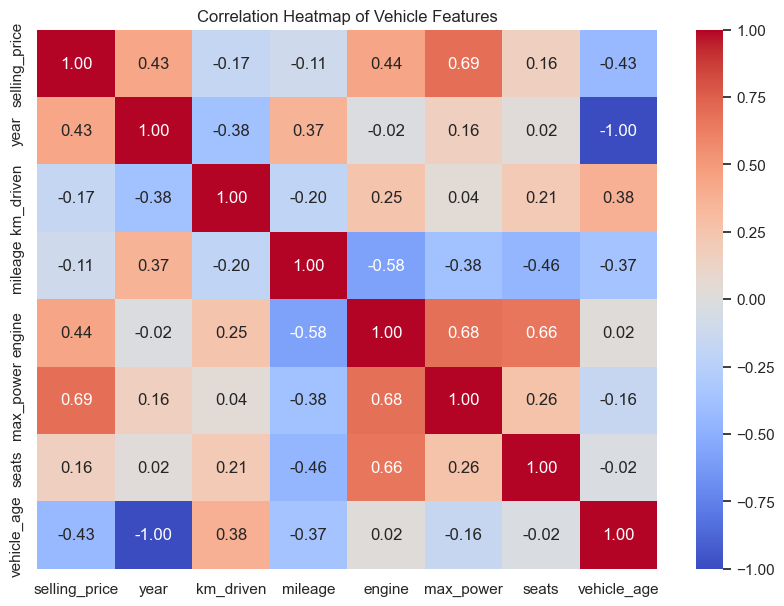

In [55]:
numeric_columns = [
    "selling_price",
    "year",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats",
    "vehicle_age"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Vehicle Features")

plt.show()

In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [57]:
# Independent variables
X = df.drop(columns=['selling_price'])

# Remove torque if it is still present as unprocessed text
if 'torque' in X.columns:
    X = X.drop(columns=['torque'])

# Dependent variable
y = df['selling_price']

print("Features:", X.columns.tolist())
print("Target:", y.name)

print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['name', 'year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'seats', 'brand', 'vehicle_age', 'km_group']
Target: selling_price
X shape: (6926, 14)
y shape: (6926,)


In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5540
Testing samples: 1386


In [59]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'vehicle_age']
Categorical features: ['name', 'fuel', 'seller_type', 'transmission', 'owner', 'brand', 'km_group']


In [60]:
models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        random_state=42
    )
}

In [61]:
trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

    print(name, "trained successfully!")

results_df = pd.DataFrame(results)

display(results_df)

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!


,Model,MAE,RMSE,R2 Score
0,Linear Regression,99450.721520,240678.410317,0.735885
1,Decision Tree,90978.074916,168471.378384,0.870589
2,Random Forest,69420.752400,123165.968445,0.930833
3,Gradient Boosting,86635.350973,137983.222069,0.913190


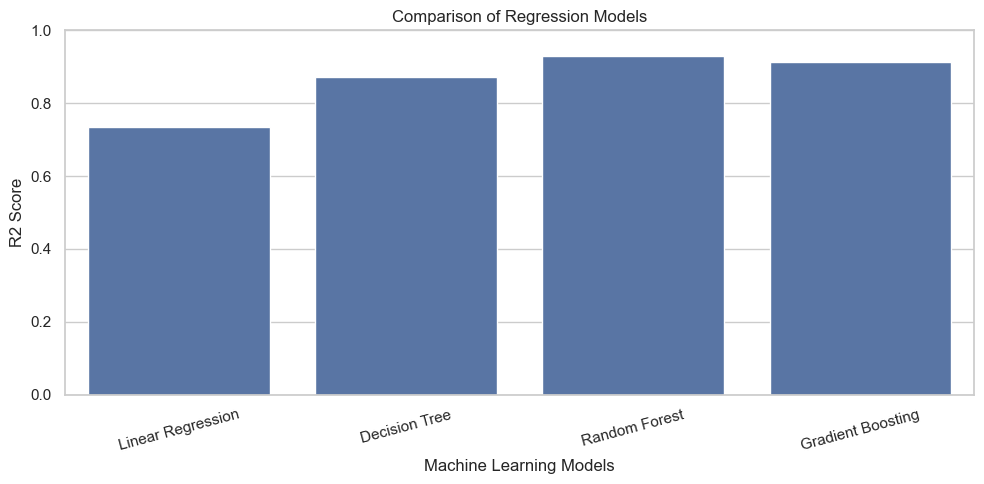

In [62]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title('Comparison of Regression Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('R2 Score')

plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

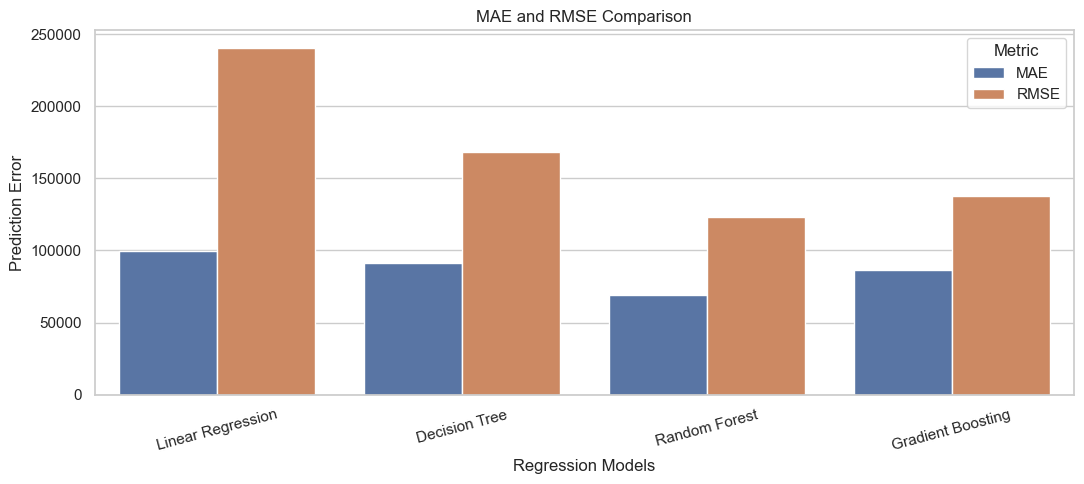

In [63]:
results_melted = results_df.melt(
    id_vars='Model',
    value_vars=['MAE', 'RMSE'],
    var_name='Metric',
    value_name='Error'
)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=results_melted,
    x='Model',
    y='Error',
    hue='Metric'
)

plt.title('MAE and RMSE Comparison')
plt.xlabel('Regression Models')
plt.ylabel('Prediction Error')

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [64]:
best_model_name = results_df.loc[
    results_df['R2 Score'].idxmax(),
    'Model'
]

best_model = trained_models[best_model_name]

print("Best Performing Model:", best_model_name)

print(
    "Best R2 Score:",
    round(results_df['R2 Score'].max(), 4)
)

Best Performing Model: Random Forest
Best R2 Score: 0.9308


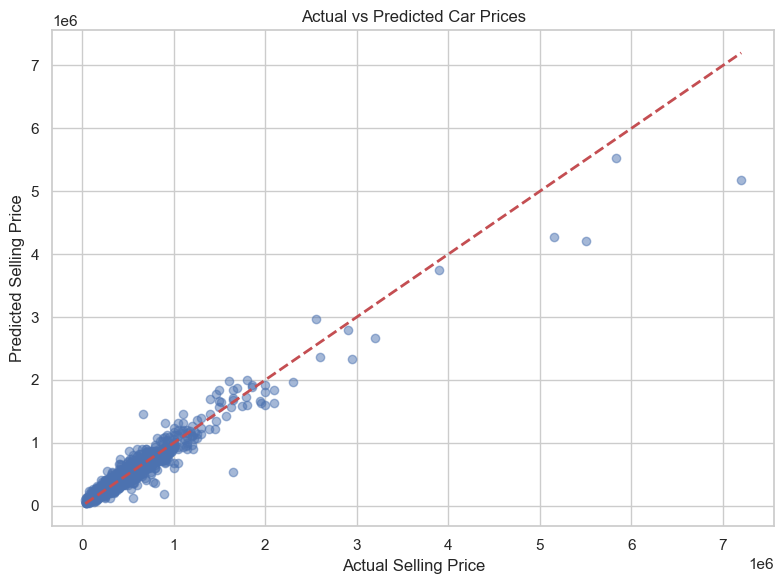

In [65]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--',
    linewidth=2
)

plt.xlabel('Actual Selling Price')
plt.ylabel('Predicted Selling Price')

plt.title('Actual vs Predicted Car Prices')

plt.tight_layout()
plt.show()

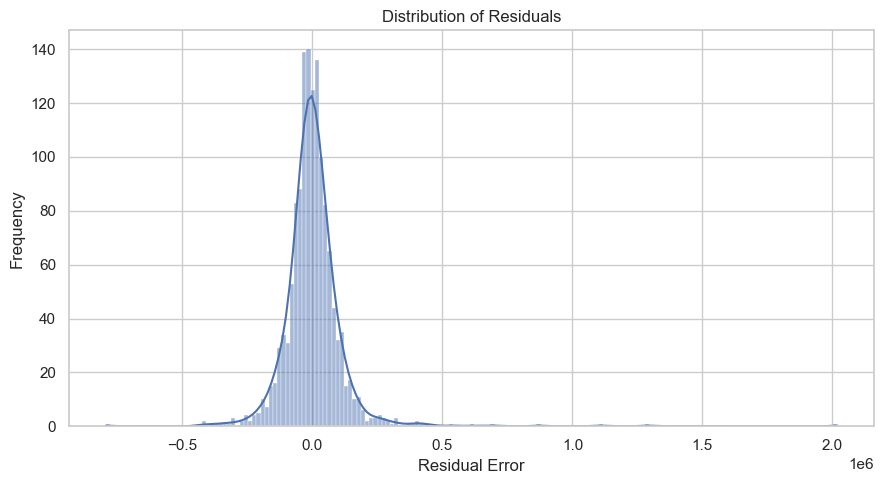

In [66]:
residuals = y_test - best_predictions

plt.figure(figsize=(9, 5))

sns.histplot(
    residuals,
    kde=True
)

plt.title('Distribution of Residuals')
plt.xlabel('Residual Error')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

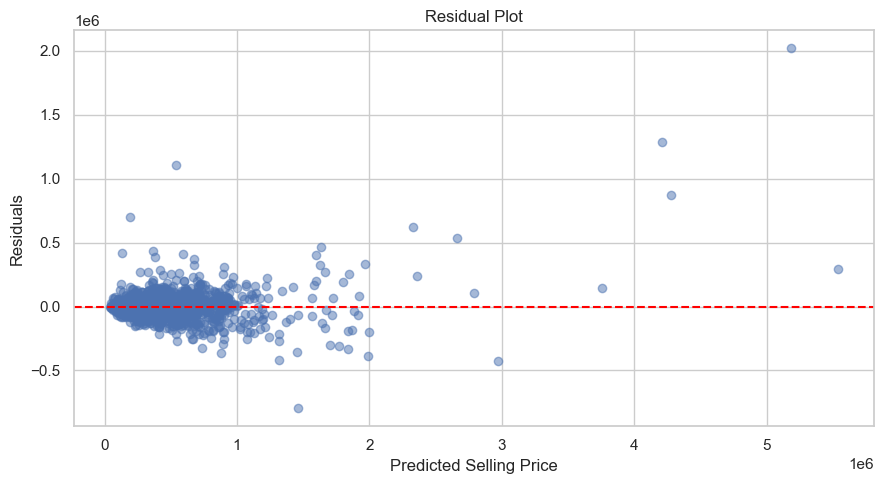

In [67]:
plt.figure(figsize=(9, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel('Predicted Selling Price')
plt.ylabel('Residuals')

plt.title('Residual Plot')

plt.tight_layout()
plt.show()

,Feature,Importance
4,num__max_power,0.590400
6,num__vehicle_age,0.114134
0,num__year,0.111044
1,num__km_driven,0.041236
2,num__mileage,0.030912
3,num__engine,0.020588
5,num__seats,0.008691
1897,cat__brand_Mercedes-Benz,0.005057
1906,cat__brand_Toyota,0.005029
1864,cat__name_Volvo XC90 T8 Excellence BSIV,0.004709


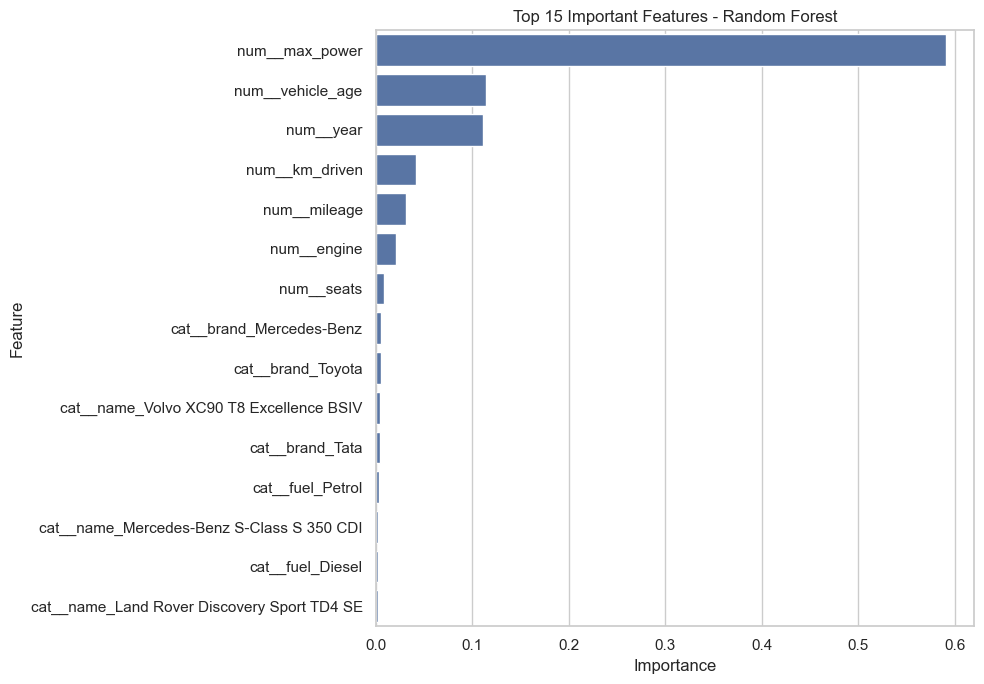

In [68]:
# Extract Random Forest model

rf_model = trained_models['Random Forest']

# Get transformed feature names

feature_names = (
    rf_model.named_steps['preprocessor']
    .get_feature_names_out()
)

# Get feature importance values

importance_values = (
    rf_model.named_steps['model']
    .feature_importances_
)

# Create dataframe

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features

display(feature_importance_df.head(15))

# Plot feature importance

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Important Features - Random Forest')

plt.tight_layout()
plt.show()

In [69]:
from sklearn.model_selection import RandomizedSearchCV

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    'model__n_estimators': [100, 200, 300, 400],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 0.8, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-random_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters:
{'model__n_estimators': 400, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': None}

Best Cross-Validation RMSE:
182885.83456963472


In [70]:
tuned_model = random_search.best_estimator_

tuned_predictions = tuned_model.predict(X_test)

tuned_mae = mean_absolute_error(
    y_test,
    tuned_predictions
)

tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_predictions)
)

tuned_r2 = r2_score(
    y_test,
    tuned_predictions
)

print("TUNED RANDOM FOREST RESULTS")
print("---------------------------")
print("MAE:", round(tuned_mae, 2))
print("RMSE:", round(tuned_rmse, 2))
print("R2 Score:", round(tuned_r2, 4))

TUNED RANDOM FOREST RESULTS
---------------------------
MAE: 69477.35
RMSE: 123506.77
R2 Score: 0.9304


In [71]:
original_rf = trained_models['Random Forest']

original_predictions = original_rf.predict(X_test)

comparison_df = pd.DataFrame([
    {
        'Model': 'Original Random Forest',
        'MAE': mean_absolute_error(
            y_test, original_predictions
        ),
        'RMSE': np.sqrt(
            mean_squared_error(y_test, original_predictions)
        ),
        'R2 Score': r2_score(
            y_test, original_predictions
        )
    },
    {
        'Model': 'Tuned Random Forest',
        'MAE': tuned_mae,
        'RMSE': tuned_rmse,
        'R2 Score': tuned_r2
    }
])

display(comparison_df)

,Model,MAE,RMSE,R2 Score
0,Original Random Forest,69420.752400,123165.968445,0.930833
1,Tuned Random Forest,69477.346178,123506.773845,0.930450


In [72]:
import joblib

if tuned_r2 > r2_score(y_test, original_predictions):

    final_model = tuned_model
    print("Tuned Random Forest selected.")

else:

    final_model = original_rf
    print("Original Random Forest selected.")

joblib.dump(
    final_model,
    '/kaggle/working/used_car_price_model.pkl'
)

print("Final model saved successfully!")

Original Random Forest selected.


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/used_car_price_model.pkl'

In [ ]:
def predict_car_price(
    year,
    km_driven,
    fuel,
    seller_type,
    transmission,
    owner,
    mileage,
    engine,
    max_power,
    seats,
    brand,
    vehicle_age,
    km_group
):

    car_data = pd.DataFrame([{
        'year': year,
        'km_driven': km_driven,
        'fuel': fuel,
        'seller_type': seller_type,
        'transmission': transmission,
        'owner': owner,
        'mileage': mileage,
        'engine': engine,
        'max_power': max_power,
        'seats': seats,
        'brand': brand,
        'vehicle_age': vehicle_age,
        'km_group': km_group
    }])

    predicted_price = final_model.predict(car_data)

    return predicted_price[0]

In [ ]:
predicted_price = predict_car_price(
    year=2018,
    km_driven=40000,
    fuel='Petrol',
    seller_type='Individual',
    transmission='Manual',
    owner='First Owner',
    mileage=20.0,
    engine=1197,
    max_power=82.0,
    seats=5,
    brand='Maruti',
    vehicle_age=8,
    km_group='Low'
)

print("Predicted Selling Price:")
print(round(predicted_price, 2))

In [ ]:
from IPython.display import FileLink

FileLink('/kaggle/working/used_car_price_model.pkl')

/kaggle/working/used_car_price_model.pkl

In [ ]:
print(trained_models.keys())

NameError: name 'trained_models' is not defined

In [ ]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.read_csv("feature_engineered_car_data.csv")

X = df.drop(columns=["selling_price"])
if "torque" in X.columns:
    X = X.drop(columns=["torque"])

y = df["selling_price"]

print("Dataset:", df.shape)
print("Features:", X.shape)
print("Target:", y.shape)

Dataset: (6926, 15)
Features: (6926, 13)
Target: (6926,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5540
Testing samples: 1386


In [ ]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(random_state=42),

    'Random Forest': RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

    print(name, "trained successfully!")

results_df = pd.DataFrame(results)
display(results_df)

/Users/swayamarora/miniforge3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/swayamarora/miniforge3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/swayamarora/miniforge3/lib/python3.12/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_


Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!


,Model,MAE,RMSE,R2 Score
0,Linear Regression,97404.801786,235493.604209,0.747142
1,Decision Tree,91763.304233,167332.077037,0.872334
2,Random Forest,69611.785387,124066.485818,0.929818
3,Gradient Boosting,86694.959532,138239.667727,0.912867


In [ ]:
final_model = trained_models['Random Forest']

joblib.dump(final_model, 'used_car_price_model.pkl')

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [75]:

import streamlit as st
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from datetime import datetime

# -----------------------------------
# 1. PAGE CONFIGURATION
# -----------------------------------

st.set_page_config(
    page_title="Used Car Price Predictor",
    page_icon="🚗",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent

MODEL_PATH = BASE_DIR / "used_car_price_model.pkl"
DATA_PATH = BASE_DIR / "feature_engineered_car_data.csv"


# -----------------------------------
# 2. LOAD MODEL AND DATASET
# -----------------------------------

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)


@st.cache_data
def load_data():
    return pd.read_csv(DATA_PATH)


try:
    model = load_model()
    data = load_data()

except FileNotFoundError as e:
    st.error(f"Required project file not found: {e}")
    st.stop()

except Exception as e:
    st.error(f"Error loading model or dataset: {e}")
    st.stop()


# -----------------------------------
# 3. RECREATE KM_GROUP FEATURE
# -----------------------------------

data["km_group"], km_bins = pd.cut(
    data["km_driven"],
    bins=20,
    retbins=True
)


# -----------------------------------
# 4. PREPARE DROPDOWN OPTIONS
# -----------------------------------

car_names = sorted(data["name"].dropna().unique())

fuel_types = sorted(data["fuel"].dropna().unique())

seller_types = sorted(data["seller_type"].dropna().unique())

transmissions = sorted(data["transmission"].dropna().unique())

owners = sorted(data["owner"].dropna().unique())

seats_options = sorted(data["seats"].dropna().unique())


# Automatically map car names to brands
brand_mapping = (
    data.groupby("name")["brand"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0])
    .to_dict()
)


# -----------------------------------
# 5. APPLICATION HEADER
# -----------------------------------

st.title("🚗 Used Car Price Prediction")

st.write(
    "Predict the estimated selling price of a used car "
    "using our Machine Learning model."
)

st.divider()

st.subheader("Enter Your Car Details")

st.info(
    "Fill in the vehicle details below to get an estimated "
    "selling price in Indian Rupees (₹)."
)


# -----------------------------------
# 6. USER INPUT FORM
# -----------------------------------

with st.form("car_prediction_form"):

    col1, col2 = st.columns(2)

    with col1:

        st.markdown("### Vehicle Information")

        name = st.selectbox(
            "Car Name",
            car_names
        )

        brand = brand_mapping[name]

        st.text_input(
            "Brand",
            value=str(brand),
            disabled=True
        )

        year = st.number_input(
            "Manufacturing Year",
            min_value=int(data["year"].min()),
            max_value=datetime.now().year,
            value=min(2018, datetime.now().year),
            step=1
        )

        km_driven = st.number_input(
            "Kilometres Driven",
            min_value=0,
            max_value=2000000,
            value=int(data["km_driven"].median()),
            step=1000
        )

        fuel = st.selectbox(
            "Fuel Type",
            fuel_types
        )

        transmission = st.selectbox(
            "Transmission",
            transmissions
        )

        owner = st.selectbox(
            "Owner Type",
            owners
        )

    with col2:

        st.markdown("### Technical Specifications")

        seller_type = st.selectbox(
            "Seller Type",
            seller_types
        )

        mileage = st.number_input(
            "Mileage (km/l)",
            min_value=0.0,
            value=float(data["mileage"].median()),
            step=0.1
        )

        engine = st.number_input(
            "Engine Capacity (CC)",
            min_value=0.0,
            value=float(data["engine"].median()),
            step=10.0
        )

        max_power = st.number_input(
            "Maximum Power (bhp)",
            min_value=0.0,
            value=float(data["max_power"].median()),
            step=1.0
        )

        seats = st.selectbox(
            "Number of Seats",
            seats_options
        )

    st.divider()

    submitted = st.form_submit_button(
        "🔍 Predict Selling Price",
        use_container_width=True
    )


# -----------------------------------
# 7. PRICE PREDICTION
# -----------------------------------

if submitted:

    vehicle_age = datetime.now().year - int(year)

    # Recreate the same kilometre group used during training
    km_group = pd.cut(
        [km_driven],
        bins=km_bins
    )[0]

    if pd.isna(km_group):
        st.warning(
            "The entered kilometres are outside the training "
            "dataset range. The model will handle the missing "
            "kilometre group using its trained imputer."
        )

    # Create input with the exact training features
    input_data = pd.DataFrame([{
        "name": name,
        "year": year,
        "km_driven": km_driven,
        "fuel": fuel,
        "seller_type": seller_type,
        "transmission": transmission,
        "owner": owner,
        "mileage": mileage,
        "engine": engine,
        "max_power": max_power,
        "seats": seats,
        "brand": brand,
        "vehicle_age": vehicle_age,
        "km_group": km_group
    }])

    try:

        prediction = model.predict(input_data)[0]

        st.divider()

        st.success("Prediction Generated Successfully!")

        st.subheader("Estimated Car Selling Price")

        st.metric(
            label="Predicted Selling Price",
            value=f"₹ {prediction:,.0f}"
        )

        st.caption(
            "This is an estimated price generated by the "
            "Random Forest model. Actual market prices may vary."
        )

        with st.expander("View submitted car details"):
            st.dataframe(input_data, use_container_width=True)

    except Exception as e:

        st.error(f"Prediction failed: {e}")


# -----------------------------------
# 8. FOOTER
# -----------------------------------

st.divider()

st.caption(
    "Used Car Price Prediction | Machine Learning Project | "
    "Final Model: Random Forest Regressor"
)


2026-11-22 23:49:25.609 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


NameError: name '__file__' is not defined